In [1]:
import yaml
import warnings

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as pl
import seaborn as sns
from pathlib import Path
from tqdm.auto import tqdm

# make figures paper quality
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
matplotlib.rcParams['font.family'] = 'sans-serif'
matplotlib.rcParams['font.sans-serif'] = 'Arial'

# Remove warning, we like to live dangerously
warnings.filterwarnings("ignore")

# load functions from ../utils
import sys
sys.path.append('../utils')
from utils import get_nnmd, annotate_essentiality

# Get config settings
with open('../configuration/config.yaml', "r") as file:
    config = yaml.load(file, Loader=yaml.FullLoader)
cell_line_dict=config['cell_lines']

In [67]:
gene_df = pd.read_csv('../results/merged/gene_results.csv', index_col=0)

In [68]:
gene_df

,Gscreend_FDR,Gscreend_pvalue,Gscreend_LFC,Gscreend_cell_line_specificity,MAGeCK_filtered_score,MAGeCK_filtered_p-value,MAGeCK_filtered_fdr,MAGeCK_filtered_lfc,MAGeCK_score,MAGeCK_p-value,MAGeCK_fdr,MAGeCK_lfc,Bagel2_filtered_Bayesfactor,Bagel2_filtered_FDR,Bagel2_Bayesfactor,Bagel2_FDR
AATBC,1.0,1.000000,0.224941,0.0,0.982900,0.744970,0.853306,0.076785,0.996410,0.887360,0.974931,0.069155,-124.940,0.113,-256.648,0.133
ACKR2,NaN,NaN,NaN,NaN,0.891700,0.248520,0.364833,-0.202520,0.580970,0.264010,0.457302,-0.026468,-41.471,0.000,-84.351,0.012
ACTA2-AS1,1.0,1.000000,0.181879,0.0,0.984300,0.728860,0.910502,0.088836,0.975640,0.925350,1.000000,0.067691,-131.842,0.116,-229.044,0.134
ACTB,0.0,0.000000,-5.811671,0.0,0.001057,0.000005,0.000036,-3.855500,0.000979,0.000015,0.000226,-2.153600,1111.133,0.000,1219.653,0.000
ACTG1,0.0,0.000000,-5.650976,0.0,0.000782,0.000005,0.000036,-2.905100,0.000233,0.000005,0.000091,-2.855300,1438.638,0.000,1527.301,0.000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZNF728,1.0,1.000000,0.120407,0.0,0.992880,0.773820,0.882815,0.042173,0.922240,0.424220,0.798411,-0.021388,-84.723,0.074,-135.559,0.043
ZNF93,1.0,1.000000,-1.782027,0.0,0.853860,0.038942,0.062821,-0.338670,0.619470,0.121840,0.312696,-0.154090,59.520,0.000,16.941,0.000
ZNHIT2,1.0,1.000000,-0.087405,0.0,0.942890,0.619660,0.775464,-0.120450,0.978970,0.671820,0.974931,-0.019170,-68.152,0.056,-135.860,0.043
ZRANB2,1.0,0.855685,-1.607866,0.0,0.330060,0.006550,0.016579,-0.455790,0.401100,0.119440,0.309789,-0.099956,313.180,0.000,302.407,0.000


# MAGECK Vulcano

In [69]:
gene_cdf = pd.read_csv('../results/merged/gene_results_perline.csv', index_col=0, header=[0,1])
gene_cdf = gene_cdf[gene_cdf.index!='NT_Control']  # remove control
final_gene_list = pd.read_csv('../resources/symp_101_final_gene_list.csv', index_col=0)
gene_cdf['is_final'] = gene_cdf.index.isin(final_gene_list.index)
gene_cdf['essentiality'] = annotate_essentiality(gene_cdf.index)

In [70]:
gene_cdf

A549                                         \
          Bagel2_Bayesfactor Bagel2_FDR Bagel2_filtered_Bayesfactor   
AATBC                -77.124      0.138                     -60.808   
ACKR2                -15.612      0.009                      -1.521   
ACTA2-AS1            -54.732      0.104                     -45.999   
ACTB                 413.281      0.000                     635.087   
ACTG1                466.985      0.000                     662.590   
...                      ...        ...                         ...   
ZNF728               -40.577      0.063                     -41.621   
ZNF93                -32.504      0.038                     -38.090   
ZNHIT2               -43.076      0.073                     -35.607   
ZRANB2               -10.682      0.009                      13.323   
ZSWIM3               -42.353      0.073                     -31.919   

                                                                         \
          Bagel2_filtered_FDR Gscreend_FDR Gscreend_LFC Gscreend_pvalue   
AATBC                   0.131          1.0     0.260911             1.0   
ACKR2                   0.000          NaN          NaN             NaN   
ACTA2-AS1               0.089          1.0     0.181879             1.0   
ACTB                    0.000          0.0    -3.441586             0.0   
ACTG1                   0.000          0.0    -3.066509             0.0   
...                       ...          ...          ...             ...   
ZNF728                  0.092          1.0     0.120407             1.0   
ZNF93                   0.089          1.0     0.037678             1.0   
ZNHIT2                  0.080          1.0    -0.087405             1.0   
ZRANB2                  0.000          1.0     0.092609             1.0   
ZSWIM3                  0.065          1.0    -0.114863             1.0   

                                                                    ...  \
          MAGeCK_fdr MAGeCK_filtered_fdr MAGeCK_filtered_goodsgrna  ...   
AATBC       0.974931            0.853306                       0.0  ...   
ACKR2       0.668082            0.364833                       1.0  ...   
ACTA2-AS1   1.000000            0.910502                       1.0  ...   
ACTB        0.001492            0.000053                       4.0  ...   
ACTG1       0.000107            0.000053                       5.0  ...   
...              ...                 ...                       ...  ...   
ZNF728      0.798411            0.976817                       0.0  ...   
ZNF93       0.312696            0.062821                       1.0  ...   
ZNHIT2      0.974931            0.775464                       1.0  ...   
ZRANB2      0.309789            0.026259                       5.0  ...   
ZSWIM3      0.725769            0.879513                       1.0  ...   

                            H1975                                             \
          MAGeCK_filtered_p-value MAGeCK_filtered_rank MAGeCK_filtered_score   
AATBC                    0.787340                626.0              0.971340   
ACKR2                    0.487620                514.0              0.891700   
ACTA2-AS1                0.806440                652.0              0.960640   
ACTB                     0.000005                 47.0              0.000997   
ACTG1                    0.000005                 26.0              0.000243   
...                           ...                  ...                   ...   
ZNF728                   0.999320                700.0              0.992880   
ZNF93                    0.177080                471.0              0.853860   
ZNHIT2                   0.920270                608.0              0.932830   
ZRANB2                   0.006550                300.0              0.330060   
ZSWIM3                   0.523850                480.0              0.790660   

                                                                               \
          MAGeCK_goodsgrna

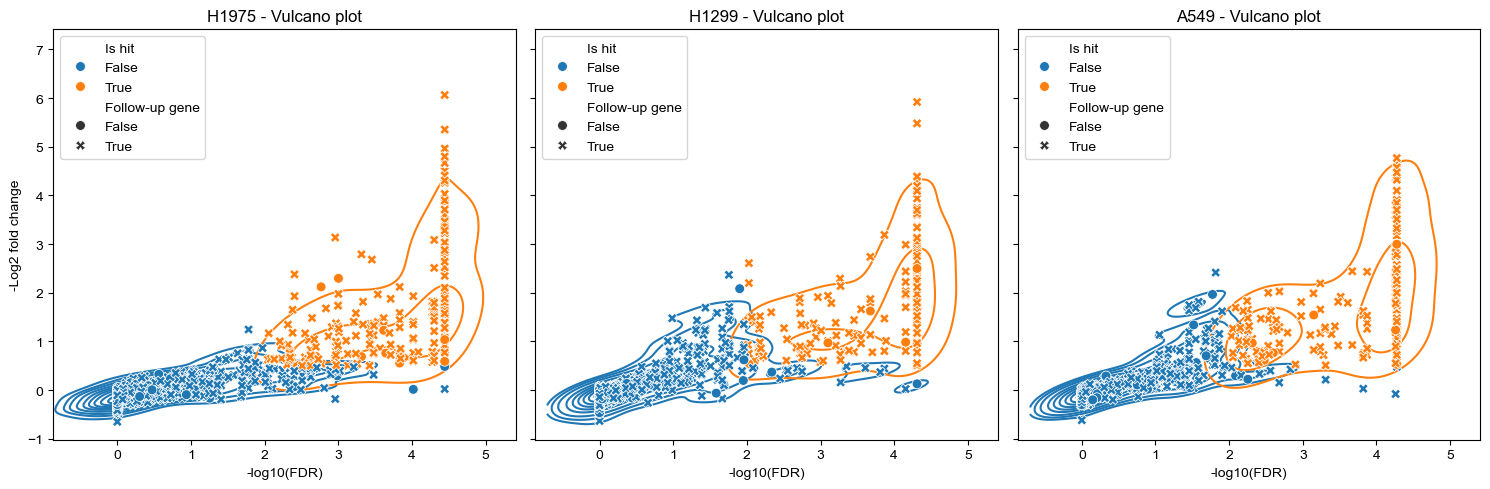

In [113]:
# Vulcano plot
fig, axs = pl.subplots(1, 3, figsize=(15, 5), sharey=True, sharex=True)
for cell_line, ax in zip(cell_line_dict.values(), axs):
    use_filtered = True
    filtered_key = '_filtered' if use_filtered else ''
    palette = {True: 'tab:orange', False: 'tab:blue'}

    gene_cdf[(cell_line, 'is_hit')] = (gene_cdf[(cell_line, f'MAGeCK{filtered_key}_fdr')] < 0.01) & (gene_cdf[cell_line, f'MAGeCK{filtered_key}_lfc'] < -0.5)
    gene_cdf[(cell_line, 'score')] = -np.log10(gene_cdf.loc[:, (cell_line, f'MAGeCK{filtered_key}_fdr')])

    x = gene_cdf[(cell_line, 'score')]
    y = -gene_cdf[(cell_line, f'MAGeCK{filtered_key}_lfc')]
    hue = gene_cdf[(cell_line, 'is_hit')]

    sns.kdeplot(data=gene_cdf, x=x, y=y, hue=hue, fill=False, ax=ax, palette=palette, zorder=1)
    sns.scatterplot(data=gene_cdf, y=y, x=x, ax=ax, hue=hue, style='is_final', palette=palette, s=50, zorder=2)
    ax.set_xlabel('-log10(FDR)')
    ax.set_ylabel('-Log2 fold change')
    ax.set_title(f'{cell_line} - Vulcano plot')
    ax.legend_.get_texts()[0].set_text('Is hit')
    ax.legend_.get_texts()[3].set_text('Follow-up gene')
pl.tight_layout()
pl.show()

# Comparisons

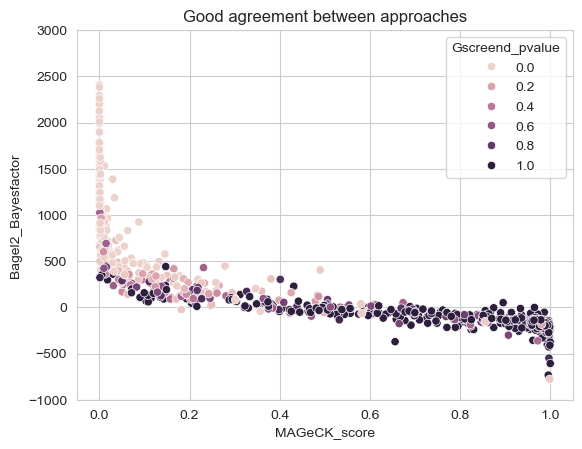

In [ ]:
# Correlate MAGeCK and BAGEL2
with sns.axes_style('whitegrid'):
    sns.scatterplot(data=gene_df, x='MAGeCK_score', y='Bagel2_Bayesfactor', hue='Gscreend_pvalue')
pl.title('Good agreement between approaches')
pl.ylim(-1000, 3000)
pl.show()

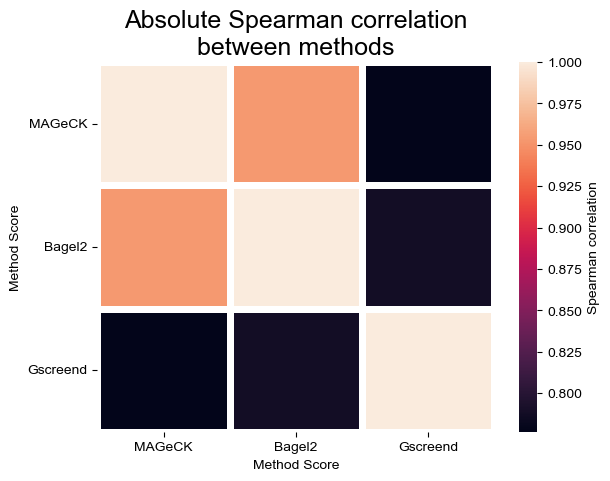

In [4]:
# Correlate all methods used
spearman = gene_df[['MAGeCK_score', 'Bagel2_Bayesfactor', 'Gscreend_pvalue']].corr(method='spearman').abs()
sns.heatmap(spearman, annot=False, linewidths=5, linecolor='white', cbar_kws={'label': 'Spearman correlation'})
pl.title('Absolute Spearman correlation\nbetween methods', fontsize=18)
pl.xlabel('Method Score')
pl.ylabel('Method Score')
pl.xticks(ticks=[0.5, 1.5, 2.5], labels=['MAGeCK', 'Bagel2', 'Gscreend'])
pl.yticks(ticks=[0.5, 1.5, 2.5], labels=['MAGeCK', 'Bagel2', 'Gscreend'], rotation=0)
pl.savefig('../results/stat_methods_evaluation/merged_methods_comparison_spearman.pdf', bbox_inches='tight')
pl.show()

# Evaluation with known essentiality from CRISPR-Cas9 screens

In [7]:
from sklearn.metrics import roc_curve, roc_auc_score
from matplotlib.cm import get_cmap

In [9]:
# add essential annotation
gene_df['essentiality'] = annotate_essentiality(gene_df.index)
gene_df.essentiality.value_counts()

essentiality
unknown          504
essential        199
non-essential     31
Name: count, dtype: int64

In [10]:
gene_df.head()

,Gscreend_FDR,Gscreend_pvalue,Gscreend_LFC,Gscreend_cell_line_specificity,MAGeCK_filtered_score,MAGeCK_filtered_p-value,MAGeCK_filtered_fdr,MAGeCK_filtered_lfc,MAGeCK_score,MAGeCK_p-value,MAGeCK_fdr,MAGeCK_lfc,Bagel2_filtered_Bayesfactor,Bagel2_filtered_FDR,Bagel2_Bayesfactor,Bagel2_FDR,essentiality
AATBC,1.0,1.0,0.224941,0.0,0.982900,0.744970,0.853306,0.076785,0.996410,0.887360,0.974931,0.069155,-124.940,0.113,-256.648,0.133,unknown
ACKR2,NaN,NaN,NaN,NaN,0.891700,0.248520,0.364833,-0.202520,0.580970,0.264010,0.457302,-0.026468,-41.471,0.000,-84.351,0.012,unknown
ACTA2-AS1,1.0,1.0,0.181879,0.0,0.984300,0.728860,0.910502,0.088836,0.975640,0.925350,1.000000,0.067691,-131.842,0.116,-229.044,0.134,unknown
ACTB,0.0,0.0,-5.811671,0.0,0.001057,0.000005,0.000036,-3.855500,0.000979,0.000015,0.000226,-2.153600,1111.133,0.000,1219.653,0.000,essential
ACTG1,0.0,0.0,-5.650976,0.0,0.000782,0.000005,0.000036,-2.905100,0.000233,0.000005,0.000091,-2.855300,1438.638,0.000,1527.301,0.000,unknown


In [11]:
def plot_roc(df, key, flip_sign=False, ax=None):
    ax = pl.subplots(figsize=(4,4))[1] if ax is None else ax

    mask = (df.essentiality!='unknown') & ~df[key].isna()
    fpr, tpr, thresholds = roc_curve(df[mask].essentiality=='essential', (1-2*int(flip_sign)) * df[mask][key])

    ax.plot(fpr, tpr, linewidth=2, label=key)
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.set_title(f'{key} ROC Curve\n(n={mask.sum()} genes)')
    

In [12]:
scores = ['MAGeCK_filtered_score', 'MAGeCK_score', 'Bagel2_filtered_Bayesfactor', 'Bagel2_Bayesfactor']
scores_filtered = ['MAGeCK_filtered_score', 'Bagel2_filtered_Bayesfactor']

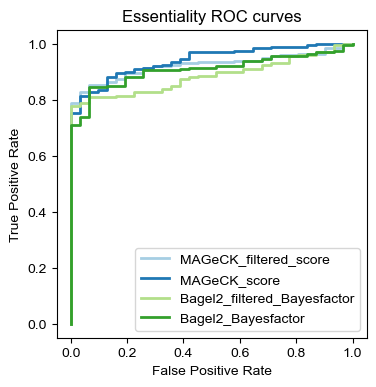

In [13]:
ax = pl.subplots(figsize=(4,4))[1]
import matplotlib.cm as cm
ax.set_prop_cycle('color', cm.get_cmap('Paired')(np.arange(0,4)))
for score, flip in zip(scores, [True, True, False, False]):
    plot_roc(gene_df, score, flip_sign=flip, ax=ax)
ax.legend()
ax.set_title('Essentiality ROC curves')
pl.savefig(f'../results/stat_methods_evaluation/joint_ROC_curves.pdf', bbox_inches='tight', dpi=300)
pl.show()

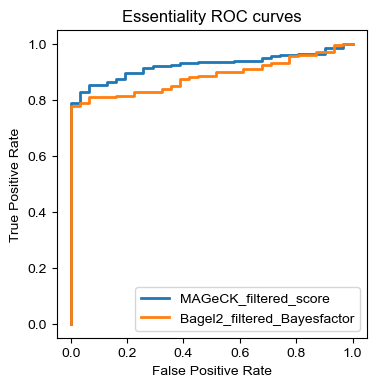

In [14]:
ax = pl.subplots(figsize=(4,4))[1]
import matplotlib.cm as cm
for score in scores_filtered:
    flip = 'MAGeCK' in score
    plot_roc(gene_df, score, flip_sign=flip, ax=ax)
ax.legend()
ax.set_title('Essentiality ROC curves')
pl.savefig(f'../results/stat_methods_evaluation/joint_ROC_curves_filtered.pdf', bbox_inches='tight', dpi=300)
pl.show()

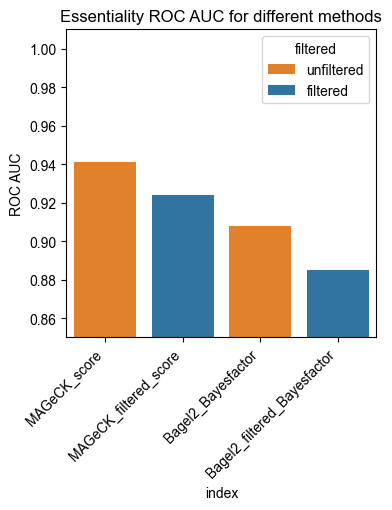

In [13]:
# ROC AUC scores
def get_auc(df, key, flip_sign=False):
    mask = (df.essentiality!='unknown') & ~df[key].isna()
    auc = roc_auc_score(df[mask].essentiality=='essential', (1-2*int(flip_sign)) * df[mask][key])
    if auc < 0.5:
        auc = 1-auc # flipped signs
    return auc

scores = ['MAGeCK_filtered_score', 'MAGeCK_score', 'Bagel2_filtered_Bayesfactor', 'Bagel2_Bayesfactor']
score_df = pd.Series({score: get_auc(gene_df, score) for score in scores}).to_frame()
score_df['filtered'] = ['filtered' if 'filtered' in x else 'unfiltered' for x in score_df.index]
score_df = score_df.sort_values(0, ascending=False)

fig, ax = pl.subplots(figsize=(4,4))
sns.barplot(data=score_df.reset_index(), x='index', y=0, hue='filtered', dodge=False, palette={'filtered': 'tab:blue', 'unfiltered': 'tab:orange'})
pl.xticks(rotation=45, ha='right')
pl.ylabel('ROC AUC')
pl.title('Essentiality ROC AUC for different methods')
pl.ylim(0.85, 1.01)
pl.savefig(f'../results/stat_methods_evaluation/ROC_AUC_scores_barplot.pdf', bbox_inches='tight', dpi=300)
pl.show()

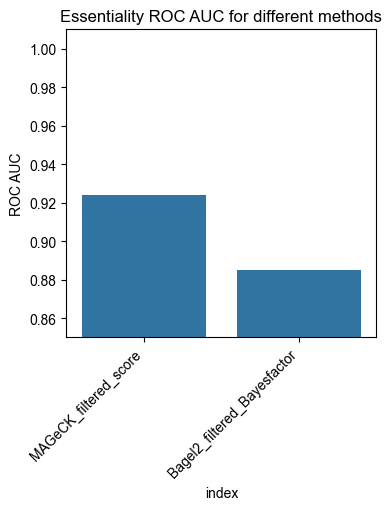

In [14]:
# ROC AUC scores
def get_auc(df, key, flip_sign=False):
    mask = (df.essentiality!='unknown') & ~df[key].isna()
    auc = roc_auc_score(df[mask].essentiality=='essential', (1-2*int(flip_sign)) * df[mask][key])
    if auc < 0.5:
        auc = 1-auc # flipped signs
    return auc

score_df = pd.Series({score: get_auc(gene_df, score) for score in scores_filtered}).to_frame()
score_df['filtered'] = ['filtered' if 'filtered' in x else 'unfiltered' for x in score_df.index]
score_df = score_df.sort_values(0, ascending=False)

fig, ax = pl.subplots(figsize=(4,4))
sns.barplot(data=score_df.reset_index(), x='index', y=0, dodge=False)
pl.xticks(rotation=45, ha='right')
pl.ylabel('ROC AUC')
pl.title('Essentiality ROC AUC for different methods')
pl.ylim(0.85, 1.01)
pl.savefig(f'../results/stat_methods_evaluation/ROC_AUC_scores_barplot_filtered.pdf', bbox_inches='tight', dpi=300)
pl.show()

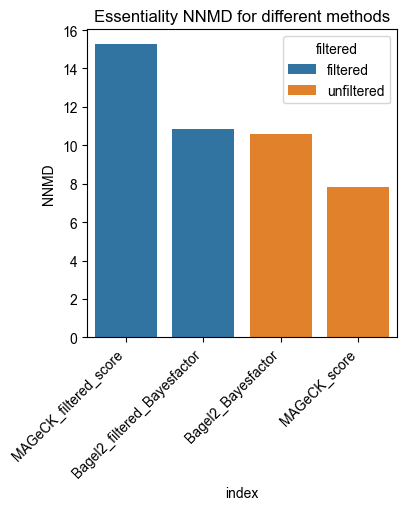

In [15]:
# NNMD
scores = ['MAGeCK_filtered_score', 'MAGeCK_score', 'Bagel2_filtered_Bayesfactor', 'Bagel2_Bayesfactor']
score_df = pd.Series({score: get_nnmd(gene_df, score) for score in scores}).to_frame()
score_df['filtered'] = ['filtered' if 'filtered' in x else 'unfiltered' for x in score_df.index]
score_df = score_df.sort_values(0, ascending=False)

fig, ax = pl.subplots(figsize=(4,4))
sns.barplot(data=score_df.reset_index(), x='index', y=0, hue='filtered', dodge=False, palette={'filtered': 'tab:blue', 'unfiltered': 'tab:orange'})
pl.xticks(rotation=45, ha='right')
pl.ylabel('NNMD')
pl.title('Essentiality NNMD for different methods')
pl.savefig(f'../results/stat_methods_evaluation/NNMD_scores_barplot.pdf', bbox_inches='tight', dpi=300)
pl.show()